# 04 · Ingestión, tiempo real e historial

Relaciona la recepción de telemetría con las consultas, las instantáneas en vivo y la exportación. Cada proceso trabaja a su propio ritmo.

[Índice del backend](README.md) · [Anterior · API y autenticación](03_api_y_autenticacion.ipynb)

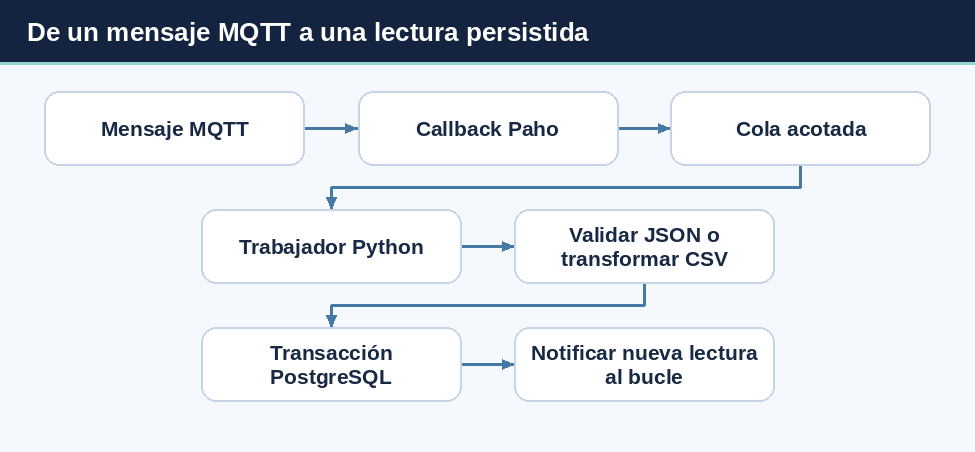

## Lectura en vivo y recuperación de pendientes

El cliente se suscribe a `dispositivo/+/tratado` y `dispositivo/+/estado`. Con `MQTT_CONVERT_RAW=true` se añade `dispositivo/+/crudo`. `+` cubre el segmento del ID del dispositivo. La suscripción solicita QoS 1; una publicación QoS 0 mantiene ese nivel de entrega efectivo.

Un JSON de `/tratado` se valida y guarda directamente. Un CSV de `/crudo` pasa por el conversor. El trabajador incorpora `record_id`, guarda la fila y publica un JSON en `/tratado`. Después de que Mosquitto confirme esa publicación, el backend envía el ID a `/ack`. Si el propio backend recibe el JSON publicado o el dispositivo reintenta la fila, la restricción `(device_id, record_id)` evita duplicar la escritura. El backend puede volver a enviar el ACK en un reintento.

Los estados `conectado` y `desconectado` actualizan la memoria del proceso. La confirmación de las suscripciones controla el indicador del broker. Al perder la conexión se limpia la caché de estados. Al reconectar, los estados retenidos pueden volver a poblarla. Los dispositivos con lecturas siguen disponibles en PostgreSQL.

## Validación, colas e hilos

`on_message` revisa forma del tema, ID del dispositivo y tamaño del cuerpo. Los eventos de medición pasan a una cola de hasta 100 elementos. Los cambios de estado se envían directamente al bucle de eventos. El hilo `mqtt-ingest` descodifica los mensajes, valida el contrato y accede a PostgreSQL. Usa `loop.call_soon_threadsafe` para notificar inserciones al bucle principal.

`parse_reading` verifica que el ID del JSON coincida con el del tema, acepta números finitos o `null` y exige desplazamiento de zona si se proporciona una fecha. `calibrate` debe ser un booleano y se traduce a `calibrated` en la base. Si se rechaza un mensaje, el backend registra el motivo.

Una **cola acotada** protege la memoria si llegan lecturas más rápido de lo que PostgreSQL las acepta. Si se llena, el ingreso descarta mensajes de medición y registra un aviso. Si falla PostgreSQL durante un pendiente, la aplicación no envía `/ack` y el dispositivo puede reenviar la fila. Una lectura directa en QoS 0 puede perderse en un fallo que ocurra después de salir del dispositivo. La espera de confirmación de un JSON de reenvío está limitada a 10 segundos y ocurre fuera del callback Paho.

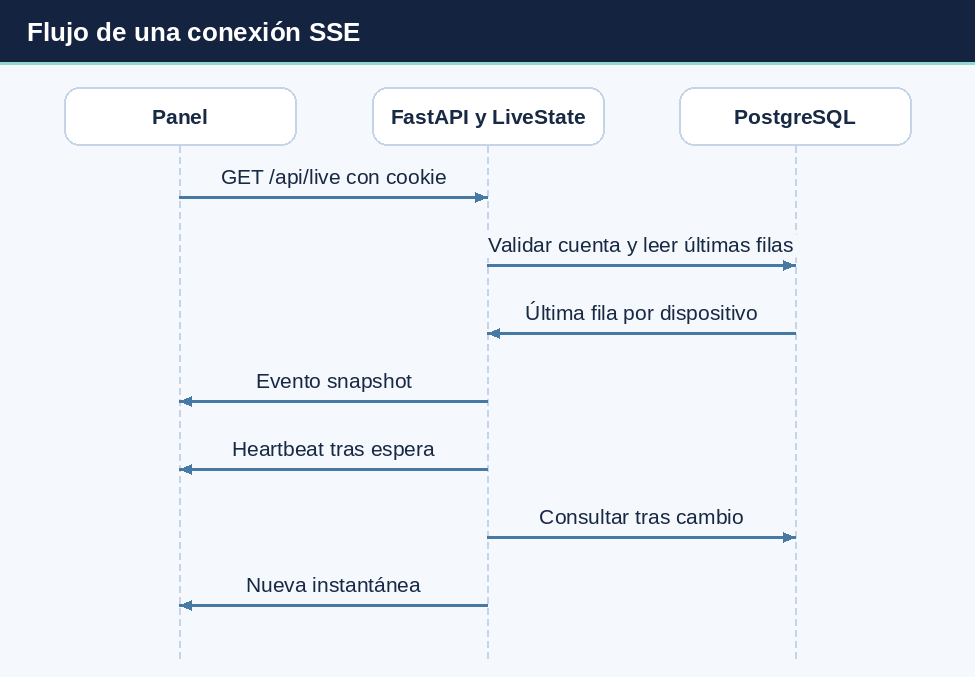

## Server-Sent Events

SSE mantiene abierta una respuesta HTTP de tipo `text/event-stream` y envía mensajes del servidor al navegador. Cada evento tiene líneas de campos y una línea vacía delimitadora. El panel utiliza solicitudes HTTP separadas para enviar acciones al servidor.

```text
event: snapshot
data: {"broker_connected":true,"devices":[]}

: heartbeat

```

Al abrir `GET /api/live`, FastAPI valida la sesión y construye una instantánea. La ruta espera un cambio en `LiveState` o un intervalo de hasta 15 segundos. Una espera agotada emite un comentario `heartbeat`. El navegador mantiene el flujo sin presentar ese comentario como lectura. La conexión termina si vence la sesión o se desconecta el cliente. Cada conexión nueva valida de nuevo la cuenta.

La consulta de última lectura usa una subconsulta lateral por dispositivo. La instantánea combina el estado temporal de los dispositivos con esas últimas lecturas. La selección descarta reenvíos identificados que llegaron sin `measured_at` para que una fila antigua sin fecha no desplace la lectura actual. Las instantáneas describen el estado disponible en el momento en que se producen. El historial permite consultar eventos individuales archivados en la base.

Un intermediario HTTP puede almacenar en búfer la respuesta SSE y demorar su entrega. La ruta envía `X-Accel-Buffering: no` para intermediarios compatibles.

## Agrupación de series

`GET /api/series?device_id=ESP32_S3_0001&period=day` calcula una ventana móvil que termina en la hora UTC de la consulta. `date_bin` agrupa las lecturas en intervalos anclados al instante de inicio.

| Periodo | Ventana móvil | Ancho de intervalo |
| --- | --- | --- |
| `day` | 24 horas | 15 minutos |
| `week` | 7 días | 4 horas |
| `month` | 30 días | 24 horas |

`AVG` ignora valores nulos de cada métrica. En un intervalo con temperaturas `20`, `22` y `NULL` el promedio es `21`. Si hubo filas en el intervalo pero una métrica no tiene valores válidos, su promedio es `null`. Si el intervalo no tiene filas, el servidor omite ese grupo. El cliente puede reconstruir huecos a partir de `start`, `end` y `step_seconds`.

Cada punto incluye un `bucket` como inicio de grupo. Como el ancla se calcula cada vez, el periodo mensual recoge los últimos 30 días en bloques de 24 horas. Los días de calendario se usan en el filtro de historial.

## Historial paginado y exportación

`GET /api/history` acepta fechas de calendario `YYYY-MM-DD` de la zona `America/Mexico_City`. El límite inicial es inclusive y el final se transforma en la medianoche siguiente al último día, exclusiva. Así `end=2026-01-15` incluye todo ese día. Las dos fechas son opcionales y el filtro usa `event_at`.

`page` empieza en 1 y `per_page` admite hasta 100 filas. El desplazamiento de la consulta es `(page - 1) * per_page`. Conteo y selección se ejecutan en una transacción PostgreSQL de solo lectura con aislamiento `REPEATABLE READ`. Así ambas consultas ven la misma versión de los datos dentro de una solicitud. Una solicitud posterior puede incluir filas nuevas.

`GET /api/history.csv` comparte filtros y entrega todas las filas que coinciden. Usa `Content-Disposition: attachment` con el nombre `monitor-aire.csv`. PostgreSQL formatea la respuesta con `COPY (...) TO STDOUT` y Python la transmite en fragmentos de aproximadamente 32 KiB. Agrega un BOM UTF-8 para favorecer la detección de codificación en hojas de cálculo. La exportación fija UTC y antepone un apóstrofo a IDs con ciertos prefijos que pueden interpretarse como fórmulas. Durante la descarga se mantiene prestada la conexión SQL.

El CSV incluye cabeceras con unidades como `temperature_c`, `humidity_rh` y `gas_ppm`. El conjunto filtrado puede abarcar más filas que una página visible.

## Diagnóstico de la telemetría

| Síntoma | Qué observar |
| --- | --- |
| La API abre y el broker nunca aparece conectado | Verifica host, puerto y permisos de suscripción. |
| Broker conectado y sin dispositivos | Confirma temas, ID del publicador y mensajes de validación en la salida del backend. |
| Hay filas en historial y faltan puntos | Compara `measured_at`, la ventana consultada y los valores nulos de cada métrica. |
| El CSV contiene más filas que la vista | Compara dispositivo y fechas. La exportación entrega todos los resultados filtrados. |
| El flujo SSE se reinicia | Revisa caducidad de la sesión, reinicios del servidor y tiempos de espera del intermediario HTTP. |
| Una fila tardó en aparecer a pesar de tener una hora antigua | Compara la hora de medición con la de recepción. El dispositivo pudo haber reenviado la lectura. |

Como práctica, inicia sesión y explora `/api/live`, `/api/series` y `/api/history.csv` en la pestaña de red del navegador. Relaciona cada respuesta con el tipo de consulta y con la vista correspondiente del panel.

[Índice del backend](README.md) · [Anterior · API y autenticación](03_api_y_autenticacion.ipynb)